## Part A | Data Quality & Basic Insights


## 1. Load and inspect

• Read the CSV using pd.read_csv(). Show head(), shape, column names and data types.

In [33]:
import os
import pandas as pd

input_file = "sales_raw.csv"  # The CSV we will practise on.
if not os.path.exists(input_file):  # Stop early with a clear message if the CSV is missing.
    raise FileNotFoundError(f"Put sales_raw.csv in this folder: {os.getcwd()}")

df = pd.read_csv(input_file)  # Load the CSV into a DataFrame named df.
print("Rows and columns:", df.shape)  
print(df.head(3).to_string(index=False))  # Show three records without extra index numbers.

Rows and columns: (21, 6)
 transaction_id sale_date region category  quantity unit_price
           1001 10/1/2026  North    food        2.0        120
           1002 10/1/2026  South    Books       1.0        250
           1003 10/2/2026  North     Food       3.0        110


In [35]:
print("\nColumn names:", df.columns.to_list())  # Show the column names as a list.


Column names: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']


In [36]:
print("data types:\n", df.dtypes)  # Show the data types of each column.

data types:
 transaction_id      int64
sale_date             str
region                str
category              str
quantity          float64
unit_price            str
dtype: object


• Check missing values with isna().sum() and duplicate rows with duplicated().sum().

In [37]:
print("Missing values by column:")
print(df.isna().sum())  # Count missing cells separately for every column.

print("Exact duplicate rows:", df.duplicated().sum())  # Count repeated entire rows.


Missing values by column:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64
Exact duplicate rows: 1


## 2. Clean the dataset



In [9]:
before = len(df)  # Save the starting row count so we can compare it later.

• Trim extra spaces and standardize inconsistent text in region and category.

In [10]:
df["region"] = df["region"].str.strip().str.title()  # Remove outer spaces and fix capitalization.
df["category"] = df["category"].str.strip().str.title()  # Standardize category labels.

• Handle missing values, invalid prices and duplicates using sensible rules; explain the choices.

**Data Cleaning Choices:**

Converted quantity and unit_price to numeric using pd.to_numeric(errors="coerce") so invalid values become NaN.
Removed rows with missing or invalid quantity or unit_price using dropna() because these fields are required for analysis.
Removed duplicate rows using drop_duplicates() to avoid duplicate records affecting results.
Used .copy() to create a clean independent DataFrame and avoid Pandas warnings.


In [11]:

df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")  # Make quantities numeric.
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")  # Make prices numeric.
df = df.dropna(subset=["quantity", "unit_price"])  # Remove rows without required numeric values.
df = df.drop_duplicates().copy()  # Keep one copy of each identical row.


Compared row counts before and after cleaning to verify how many records were removed.

In [12]:

print("Rows before cleaning:", before)  # Starting row count.
print("Rows after cleaning:", len(df))  # Expected 17 for the supplied CSV.

Rows before cleaning: 21
Rows after cleaning: 17


## 3 Calculate and analyze

Create **`revenue`**: quantity × unit_price



In [40]:
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")

df["revenue"] = (df["quantity"] * df["unit_price"]).round(2)
print(df["revenue"].head(3))


0    240.0
1    250.0
2    330.0
Name: revenue, dtype: float64


• Use groupby() to summarize revenue by region

In [41]:
region_revenue = df.groupby('region')['revenue'].sum()

print(region_revenue)

region
East       740.0
North    11800.0
SOUTH      500.0
South      275.0
West      1130.0
Name: revenue, dtype: float64


• Use groupby() to summarize revenue by category

In [42]:
category_revenue = df.groupby('category')['revenue'].sum()
print(category_revenue)

category
 food           450.0
 food           240.0
Books          1870.0
Food           1325.0
Stationery    10460.0
books           500.0
Name: revenue, dtype: float64


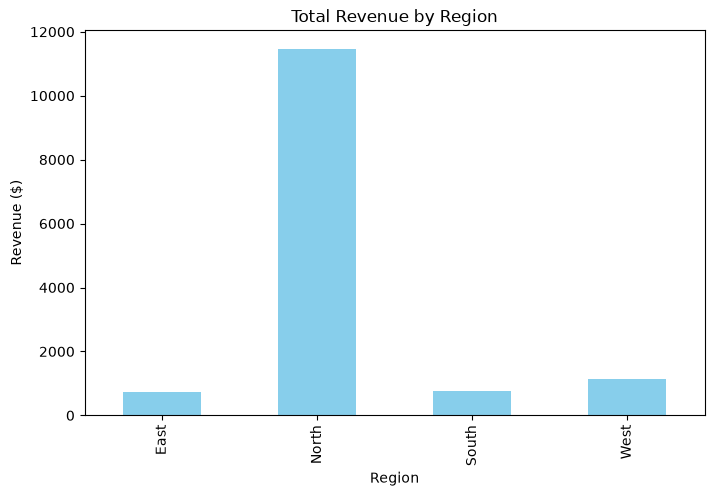

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
region_revenue.plot(kind='bar', color='skyblue')
plt.title('Total Revenue by Region')
plt.xlabel('Region')
plt.ylabel('Revenue ($)')
plt.show()

## Finding 1 

The North region generated the highest revenue of 11800.0, while the East region generated the lowest revenue. This shows that sales performance is strongest in the North region and may need improvement in the East region.

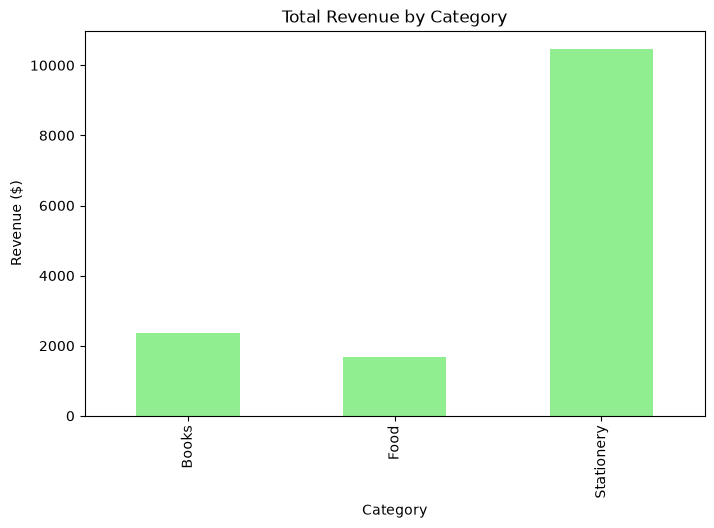

In [26]:
plt.figure(figsize=(8,5))
category_revenue.plot(kind='bar', color='lightgreen')
plt.title('Total Revenue by Category')
plt.xlabel('Category')
plt.ylabel('Revenue ($)')
plt.show()


## Finding 2
The stationery category contributed the most revenue, accounting for a larger share of total sales than other categories. In contrast, food generated  lower customer spending in that category.

## 4 — Save the result

• Export a new cleaned_sales.csv using to_csv(..., index=False).

In [43]:
df.to_csv("cleaned_sales.csv", index=False)  # Save all edited records without Pandas index labels.

## Part B CSV File Handling & Manipulation

1. Read and add a column

In [44]:
df1=pd.read_csv("cleaned_sales.csv")  


Add tax_amount equal to 5% of revenue and show the first five rows.

In [46]:
df1["tax_amount"]=df["revenue"]*0.05
df1.head()

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,10/1/2026,North,food,2.0,120.0,240.0,12.0
1,1002,10/1/2026,South,Books,1.0,250.0,250.0,12.5
2,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.5
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.0
4,1005,10/3/2026,SOUTH,books,2.0,250.0,500.0,25.0


### 2. Update and remove

• Use .loc[] to increase the unit_price of Books items by 10%; recalculate revenue and tax_amount.

In [48]:
df1["unit_price"] = pd.to_numeric(df1["unit_price"], errors="coerce")

books_mask = df1["category"].str.strip().str.lower().eq("books")
df1.loc[books_mask, "unit_price"] *= 1.10

df1["revenue"] = (df1["quantity"] * df1["unit_price"]).round(2)
df1["tax_amount"] = (df1["revenue"] * 0.05).round(2)

df1.head()  

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount,unit`_price
0,1001,10/1/2026,North,food,2.0,120.0,240.0,12.00,120.0
1,1002,10/1/2026,South,Books,1.0,275.0,275.0,13.75,250.0
2,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.50,110.0
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.00,50.0
4,1005,10/3/2026,SOUTH,books,2.0,275.0,550.0,27.50,250.0


Remove one selected row using an existing transaction_id.

In [49]:
idx = df[df['transaction_id'] == 1002].index
df.drop(idx, inplace=True)
df.head()

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,10/1/2026,North,food,2.0,120.0,240.0,12.0
2,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.5
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.0
4,1005,10/3/2026,SOUTH,books,2.0,250.0,500.0,25.0
5,1006,10/3/2026,West,Food,NaN,130.0,NaN,NaN


Create a temporary review_status column, then remove it with drop(columns=...).

In [51]:
df1["review_status"]= 'Pending'

print("After adding column:")
print(df1.head())

After adding column:
   transaction_id  sale_date region    category  quantity  unit_price  \
0            1001  10/1/2026  North       food        2.0       120.0   
1            1002  10/1/2026  South       Books       1.0       275.0   
2            1003  10/2/2026  North        Food       3.0       110.0   
3            1004  10/2/2026   East  Stationery       4.0        50.0   
4            1005  10/3/2026  SOUTH       books       2.0       275.0   

   revenue  tax_amount  unit`_price review_status  
0    240.0       12.00        120.0       Pending  
1    275.0       13.75        250.0       Pending  
2    330.0       16.50        110.0       Pending  
3    200.0       10.00         50.0       Pending  
4    550.0       27.50        250.0       Pending  


In [53]:
df1.drop(columns="review_status", inplace=True)
df1.head()


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount,unit`_price
0,1001,10/1/2026,North,food,2.0,120.0,240.0,12.00,120.0
1,1002,10/1/2026,South,Books,1.0,275.0,275.0,13.75,250.0
2,1003,10/2/2026,North,Food,3.0,110.0,330.0,16.50,110.0
3,1004,10/2/2026,East,Stationery,4.0,50.0,200.0,10.00,50.0
4,1005,10/3/2026,SOUTH,books,2.0,275.0,550.0,27.50,250.0


## 3. Save and verify

In [54]:
df1.to_csv("sales_updated.csv", index=False)  # Save all edited records without Pandas index labels.


In [55]:
df2=pd.read_csv("sales_updated.csv")  # Load the CSV into a DataFrame named df2.
print(df2.head())
print(df2.columns)

   transaction_id  sale_date region    category  quantity  unit_price  \
0            1001  10/1/2026  North       food        2.0       120.0   
1            1002  10/1/2026  South       Books       1.0       275.0   
2            1003  10/2/2026  North        Food       3.0       110.0   
3            1004  10/2/2026   East  Stationery       4.0        50.0   
4            1005  10/3/2026  SOUTH       books       2.0       275.0   

   revenue  tax_amount  unit`_price  
0    240.0       12.00        120.0  
1    275.0       13.75        250.0  
2    330.0       16.50        110.0  
3    200.0       10.00         50.0  
4    550.0       27.50        250.0  
Index(['transaction_id', 'sale_date', 'region', 'category', 'quantity',
       'unit_price', 'revenue', 'tax_amount', 'unit`_price'],
      dtype='str')
